# Example processing of FFV

In [1]:
from vast_pea.fitting import fit_wlffv

import numpy as np
import matplotlib.pyplot as plt

temperatures = range(200,620,20)

## Read FFV from LUNAR logs

In [2]:
file_template = "../../data/dilatometry/ffv_logs/system_tg.{}.log.lunar"

abs_ffv = [] # storing absolute FFV information
for t in temperatures:
    with open(file_template.format(t), 'rt') as f: # open the log file
        lines = f.readlines()

    for line in lines:
        if 'Percent Free volume   :' in line: # search for this line
            ffv_value = float(line.split(':')[1].split('%')[0].strip(' ')) # keep only the ffv value
            abs_ffv.append(ffv_value)

abs_ffv = np.array(abs_ffv) # transfer to np.array for further calculations

## Plot absolute FFV

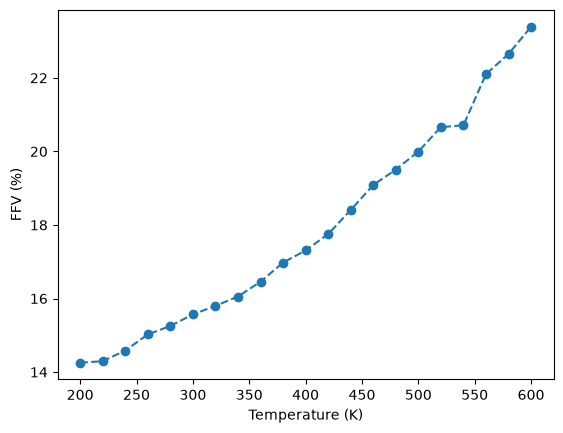

In [3]:
plt.plot(temperatures, abs_ffv, 'o--')
plt.xlabel("Temperature (K)")
plt.ylabel("FFV (%)")
plt.show()

## Fit to find FFV at Tg
This method was also used to normalize the FFV of references in the publication.
The equation used is $FFV = FFV_{Tg} + CTE_{free} * (T - Tg)$

In [4]:
fit = fit_wlffv(temperature=temperatures[:5], # temperature data
                ffv=abs_ffv[:5], # free volume data
                ffvg_ini = 20, # initial guess for free volume at Tg
                cte_ini = 50e-6, # initial guess for CTE of free volume
                tg = 401, # calculated Tg for this system
                verbose=True # print fit information
                )

norm_ffv = abs_ffv / fit.ffvg

Fitting WLF :
	FFVg : 16.88 ± 0.30 %
	CTE : 45.4 ± 6.2 1/K * 1e-6
	R^2 : 0.95


## Plot the normalized FFV

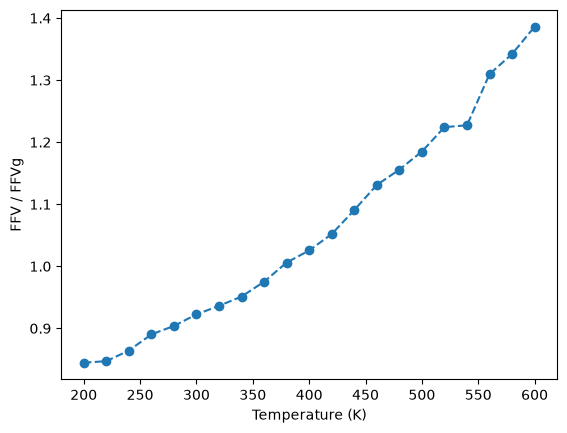

In [5]:
plt.plot(temperatures, norm_ffv, 'o--')
plt.xlabel("Temperature (K)")
plt.ylabel("FFV / FFVg")
plt.show()